**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 7**
Análisis de Componentes Principales (PCA)

---



Equipo 29

- José Antonio Guizar Pascacio, A01174201
- Isaac Antonio Gutiérrez Díaz, A01841319
- Ramón Gutiérrez Lara, A01840916
- Aarón Hernández Jiménez, A01642529

En esta actividad trabajarás con el archivo `automobile_dataset.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de automóviles, disponible en el repositorio UCI Machine Learning.

Los datos fueron recopilados para analizar diferentes aspectos de los vehículos y sus precios, e incluyen información sobre el fabricante, tipo de motor, dimensiones, peso, rendimiento de combustible y otras especificaciones técnicas. Los indicadores incluidos son:

* `symboling`: Nivel de riesgo del seguro del automóvil, de -3 (bajo riesgo) a +3 (alto riesgo)
* `normalized_losses`: Pérdidas normalizadas del seguro (valor numérico de la aseguradora, algunas veces faltante)
* `make`: Marca del automóvil (por ejemplo, Audi, BMW, Honda)
* `fuel_type`: Tipo de combustible (gasolina o diésel)
* `aspiration`: Tipo de aspiración del motor (normal o turbo)
* `num_doors`: Número de puertas del automóvil (dos o cuatro)
* `body_style`: Estilo de carrocería (sedán, hatchback, wagon, hardtop, convertible)
* `drive_wheels`: Tipo de tracción (fwd: delantera, rwd: trasera, 4wd: en las cuatro ruedas)
* `engine_location`: Ubicación del motor (delantero o trasero)
* `wheel_base`: Distancia entre ejes (en pulgadas)
* `length`: Largo total del automóvil (en pulgadas)
* `width`: Ancho total del automóvil (en pulgadas)
* `height`: Altura total del automóvil (en pulgadas)
* `curb_weight`: Peso del automóvil sin carga (en libras)
* `engine_type`: Tipo de motor (OHV, OHC, DOHC, etc.)
* `num_cylinders`: Número de cilindros del motor
* `engine_size`: Tamaño del motor (en cc)
* `fuel_system`: Sistema de combustible (por ejemplo, mpfi, 2bbl, 4bbl)
* `bore`: Diámetro del cilindro (en pulgadas)
* `stroke`: Carrera del pistón (en pulgadas)
* `compression_ratio`: Relación de compresión del motor
* `horsepower`: Potencia del motor (en caballos de fuerza)
* `peak_rpm`: Revoluciones máximas por minuto
* `city_mpg`: Rendimiento de combustible en ciudad (millas por galón)
* `highway_mpg`: Rendimiento de combustible en carretera (millas por galón)
* `price`: Precio del automóvil (en dólares estadounidenses) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

1. Descarga el archivo: `automobile_dataset.csv` y guarda, en un dataframe (`cars_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Al revisar los primeros registros, notarás que la columna `normalized_losses` contiene el símbolo `?`. Esto sugiere que se utilizó para indicar valores faltantes. Identifica todas las columnas que presentan este símbolo.
* Sustituye el símbolo `?` por valores faltantes (`NaN`) y convierte las columnas al tipo de dato adecuado. Esto es necesario porque la presencia del símbolo pudo haber hecho que pandas las interpretara como object, aunque en realidad no lo fueran.

In [2]:
# Cargar todos los registros en cars_df y revisar los tipos de datos
cars_df = pd.read_csv('automobile_dataset.csv')
cars_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    int64  
 16  engine_size        205 non

In [3]:
# Contar cuántas veces aparece '?' en cada columna
signos = (cars_df == '?').sum()
signos[signos > 0]

normalized_losses    41
bore                  4
stroke                4
horsepower            2
peak_rpm              2
dtype: int64

In [4]:
# Sustituir '?' por NaN y convertir esas columnas a número
cars_df = cars_df.replace('?', np.nan)
columnas_con_signo = signos[signos > 0].index
cars_df[columnas_con_signo] = cars_df[columnas_con_signo].apply(pd.to_numeric)
cars_df.dtypes.value_counts()

float64    10
object      9
int64       7
Name: count, dtype: int64

Respuesta 1

Al cargar el archivo y revisar la información con info(), se encontró que tenía 205 registros y 26 columnas. De estas, 12 aparecían como numéricas, 5 con decimales y 7 enteras, mientras que las otras 14 estaban como texto. Sin embargo, se notó que algunas columnas que deberían ser numéricas aparecían como texto.

Al revisar los datos, se encontraron signos de interrogación en cinco columnas: normalized_losses con 41, bore y stroke con 4 cada una, y horsepower y peak_rpm con 2 cada una. Esto sucede porque pandas interpreta toda la columna como texto cuando encuentra estos símbolos, aunque los demás valores sean números.

Para solucionar esto, se reemplazaron los signos de interrogación por NaN, que es la forma en que pandas identifica los datos faltantes, y después se convirtieron esas cinco columnas a formato numérico.

Al terminar la limpieza, quedaron 17 columnas numéricas y 9 de texto. Ahora los datos están mejor organizados y cada columna tiene el tipo de información que le corresponde. Por ejemplo, las medidas, el peso, la potencia y el precio son números, mientras que la marca, el combustible y el tipo de carrocería son texto.

# Análisis exploratorio de datos (univariado)

2. Antes de iniciar con el análisis univariado, verifica si hay registros duplicados e imprime el porcentaje de faltantes por columna.
* Obtén las estadísticas descriptivas, separado las numéricas (incluye asimetría y curtosis) y las categóricas (incluye tablas de frecuencias).
* Genera histogramas para las numéricas y diagramas de barras para las categóricas.

In [5]:
# Registros duplicados y porcentaje de faltantes por columna
print('Registros duplicados:', cars_df.duplicated().sum())
faltantes = (cars_df.isna().mean() * 100).round(2)
faltantes[faltantes > 0]

Registros duplicados: 0


normalized_losses    20.00
bore                  1.95
stroke                1.95
horsepower            0.98
peak_rpm              0.98
dtype: float64

In [6]:
# Estadísticas descriptivas de las numéricas, con asimetría y curtosis
num_df = cars_df.select_dtypes(include='number')
desc_num = num_df.describe().T
desc_num['asimetria'] = num_df.skew()
desc_num['curtosis'] = num_df.kurt()
desc_num.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
symboling,205.0,0.83,1.25,-2.00,0.00,1.00,2.00,3.00,0.21,-0.68
normalized_losses,164.0,122.00,35.44,65.00,94.00,115.00,150.00,256.00,0.77,0.53
wheel_base,205.0,98.76,6.02,86.60,94.50,97.00,102.40,120.90,1.05,1.02
length,205.0,174.05,12.34,141.10,166.30,173.20,183.10,208.10,0.16,-0.08
width,205.0,65.91,2.15,60.30,64.10,65.50,66.90,72.30,0.90,0.70
height,205.0,53.72,2.44,47.80,52.00,54.10,55.50,59.80,0.06,-0.44
curb_weight,205.0,2555.57,520.68,1488.00,2145.00,2414.00,2935.00,4066.00,0.68,-0.04
num_cylinders,205.0,4.38,1.08,2.00,4.00,4.00,4.00,12.00,2.82,13.71
engine_size,205.0,126.91,41.64,61.00,97.00,120.00,141.00,326.00,1.95,5.31
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.59,3.94,0.02,-0.83


In [7]:
# Tablas de frecuencias de las 9 variables de texto
cat_df = cars_df.select_dtypes(include='object')
for col in cat_df.columns:
    print(f'--- {col} ---')
    print(cat_df[col].value_counts(), '\n')

--- make ---
make
toyota           32
nissan           18
mazda            17
mitsubishi       13
honda            13
volkswagen       12
subaru           12
peugot           11
volvo            11
dodge             9
mercedes-benz     8
bmw               8
audi              7
plymouth          7
saab              6
porsche           5
isuzu             4
jaguar            3
chevrolet         3
alfa-romero       3
renault           2
mercury           1
Name: count, dtype: int64 

--- fuel_type ---
fuel_type
gas       185
diesel     20
Name: count, dtype: int64 

--- aspiration ---
aspiration
std      168
turbo     37
Name: count, dtype: int64 

--- num_doors ---
num_doors
four    116
two      89
Name: count, dtype: int64 

--- body_style ---
body_style
sedan          96
hatchback      70
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64 

--- drive_wheels ---
drive_wheels
fwd    120
rwd     76
4wd      9
Name: count, dtype: int64 

--- engine_location ---

In [8]:
# Estadísticas descriptivas de las categóricas: categoría más común, frecuencia y número de categorías
resumen_cat = pd.DataFrame({
    'mas_comun': cat_df.mode().iloc[0],
    'veces': [cat_df[c].value_counts().iloc[0] for c in cat_df.columns],
    'categorias': cat_df.nunique()
})
display(resumen_cat)

,mas_comun,veces,categorias
make,toyota,32,22
fuel_type,gas,185,2
aspiration,std,168,2
num_doors,four,116,2
body_style,sedan,96,5
drive_wheels,fwd,120,3
engine_location,front,202,2
engine_type,ohc,148,7
fuel_system,mpfi,94,8


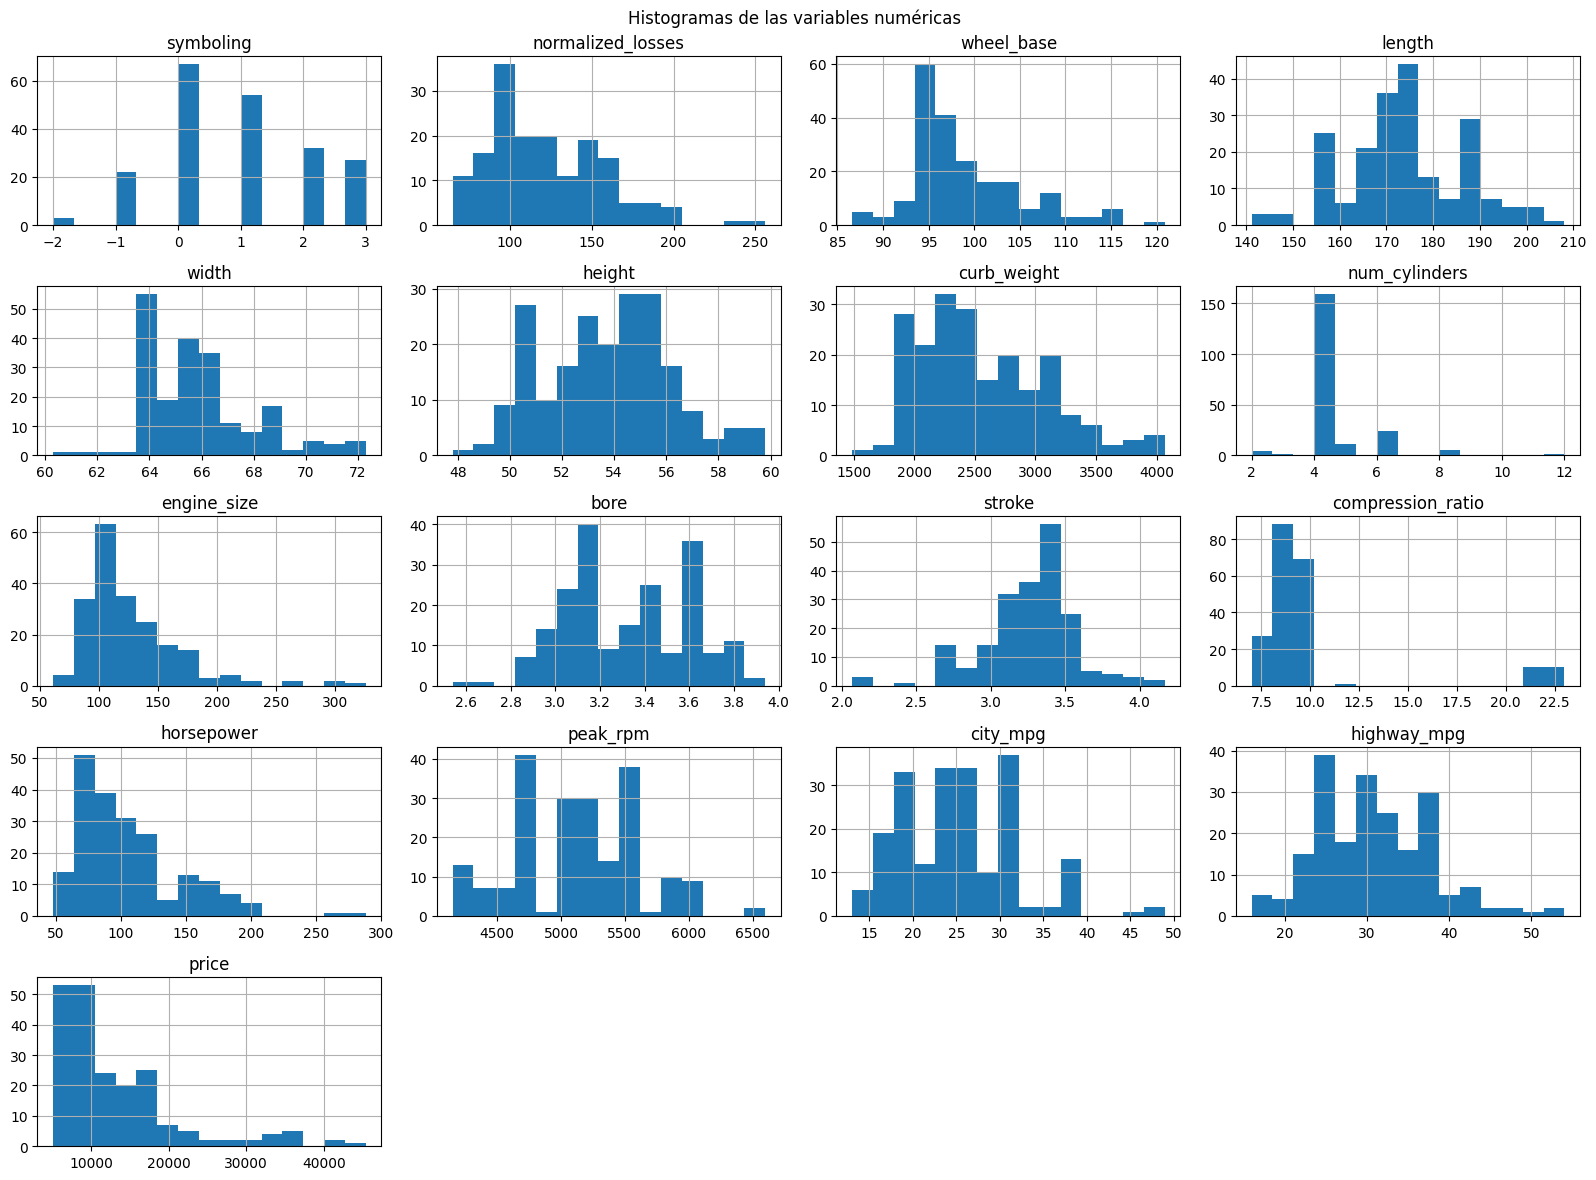

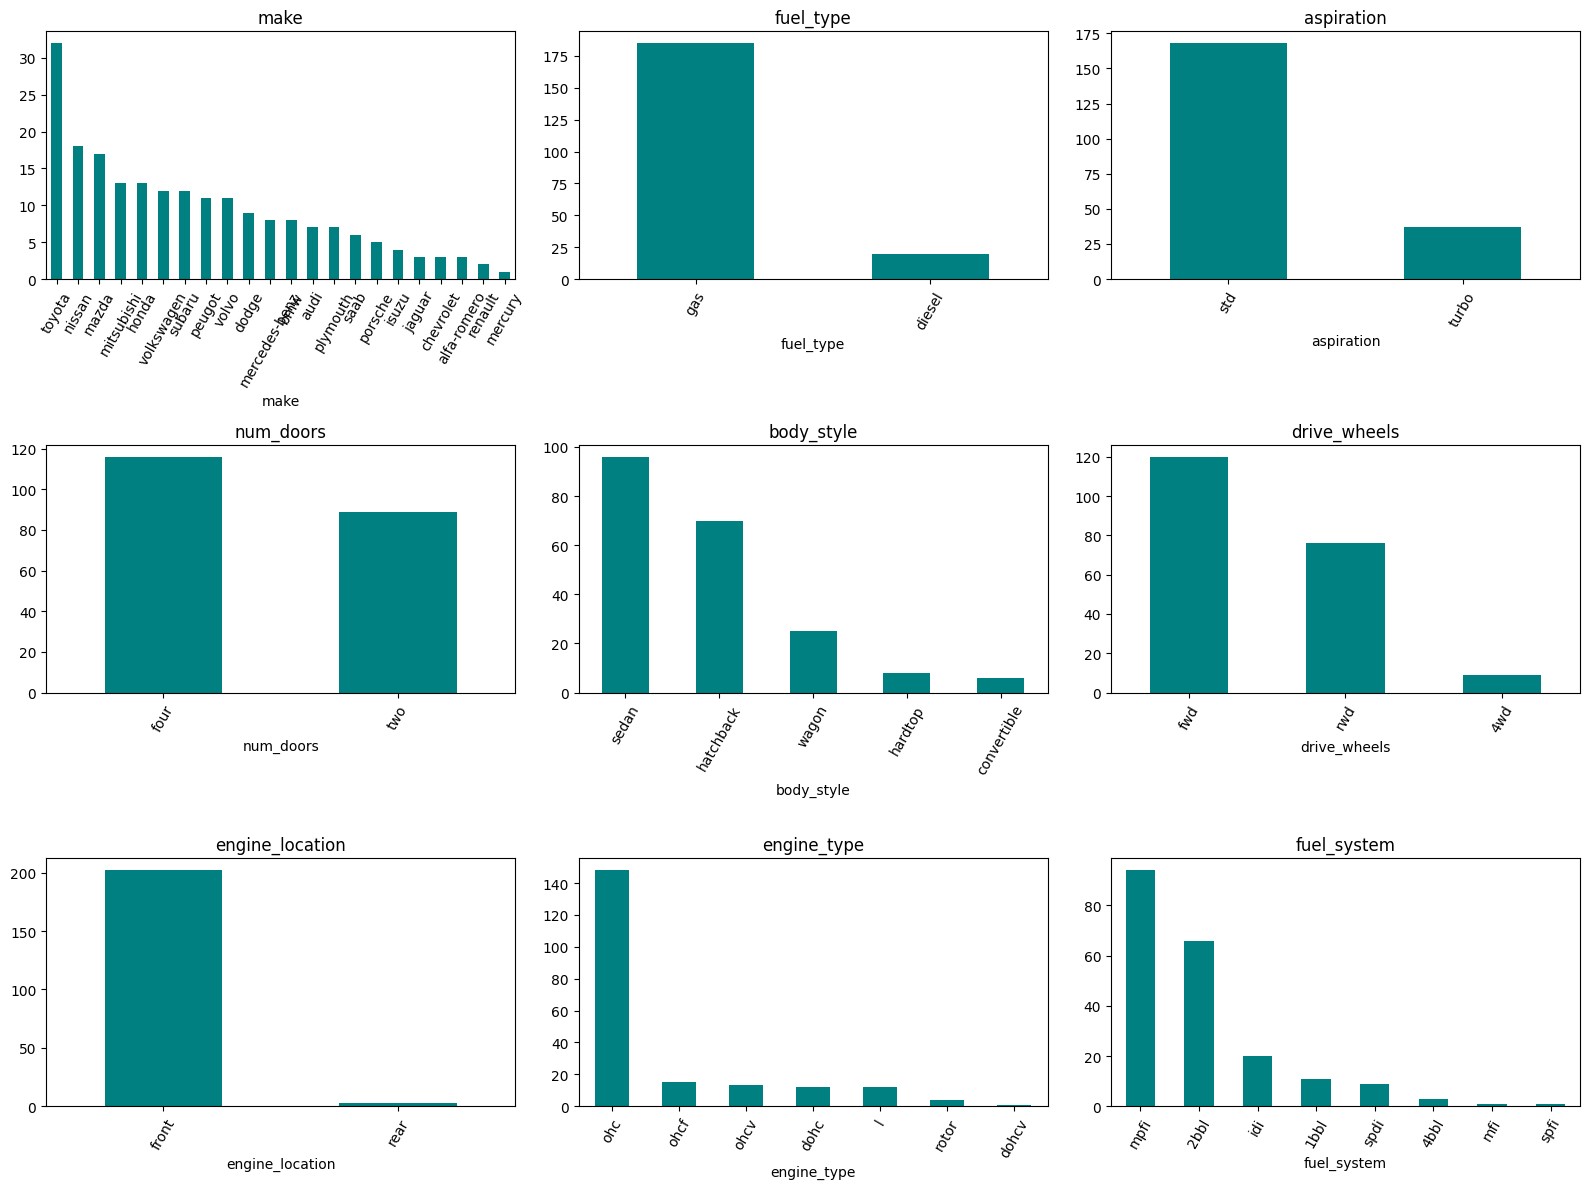

In [9]:
# Histogramas de las numéricas
num_df.hist(bins=15, figsize=(16, 12))
plt.suptitle('Histogramas de las variables numéricas')
plt.tight_layout()
plt.show()

# Barras de las categóricas
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, cat_df.columns):
    cat_df[col].value_counts().plot(kind='bar', ax=ax, color='teal')
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()

Respuesta 2

Al revisar los datos, no se encontraron registros duplicados. En cuanto a los valores faltantes, la mayoría están en la columna normalized_losses, donde falta el 20% de la información, ya que solo 164 de los 205 autos tienen ese dato. En bore y stroke falta aproximadamente el 2%, mientras que en horsepower y peak_rpm es menos del 1%. Estos últimos se pueden completar más adelante sin afectar demasiado el análisis.

En las variables numéricas, se encontró que el precio promedio de los autos es de 13,150 dólares, pero la mitad cuesta menos de 10,295 dólares y el más caro llega a 45,400. Esto indica que hay algunos autos mucho más caros que hacen que el promedio suba. Por eso, en el histograma la mayoría de los precios se concentra del lado izquierdo, con una cola larga hacia la derecha y una asimetría de 1.84. Algo parecido sucede con el tamaño del motor (1.95) y la potencia (1.39), donde unos pocos autos tienen valores mucho más altos que el resto.

Algo que llamó la atención fue la variable num_cylinders, porque la mayoría de los autos tiene 4 cilindros y solo unos cuantos tienen 8 o 12. Esto explica por qué su histograma está tan concentrado y tiene una curtosis alta de 13.71. También se observó que la relación de compresión se concentra alrededor de 9, aunque algunos autos llegan hasta 23, principalmente los de diésel. Su asimetría es de 2.61. En cambio, variables como el largo, la altura, peak_rpm y bore tienen distribuciones más equilibradas.

En las variables categóricas también se encontró que algunas opciones predominan bastante. Por ejemplo, 202 de los 205 autos tienen el motor adelante, 148 utilizan el tipo de motor ohc y 94 tienen el sistema de combustible mpfi.

En general, este análisis ayudó a entender mejor cómo están distribuidos los datos y cuáles variables podrían ser más útiles.

# Análisis exploratorio de datos (bivariado)

3. Genera algunos gráficos bivariados para familiarizarte con el conjunto de datos:
* Gráfico de barras apiladas normalizadas que muestra la distribución de los tipos de tracción para cada fabricante.
* Diagrama de cajas para visualizar cómo se distribuye el precio de los automóviles según el estilo de carrocería. Esto permitirá comparar la mediana, los cuartiles y la presencia de valores atípicos entre los diferentes tipos de carrocería.
* Gráfico de barras que muestre los 10 automóviles más caros, ordenados de mayor a menor precio, con cada barra diferenciada con color por fabricante.
* Diagrama de dispersión para explorar la relación entre el tamaño del motor y el precio de los automóviles. Diferencia con colores los puntos según el tipo de aspiración y con el tamaño de los puntos el número de puertas.

**Nota.** Debes incluir en cada gráfico una conclusión de lo observado.

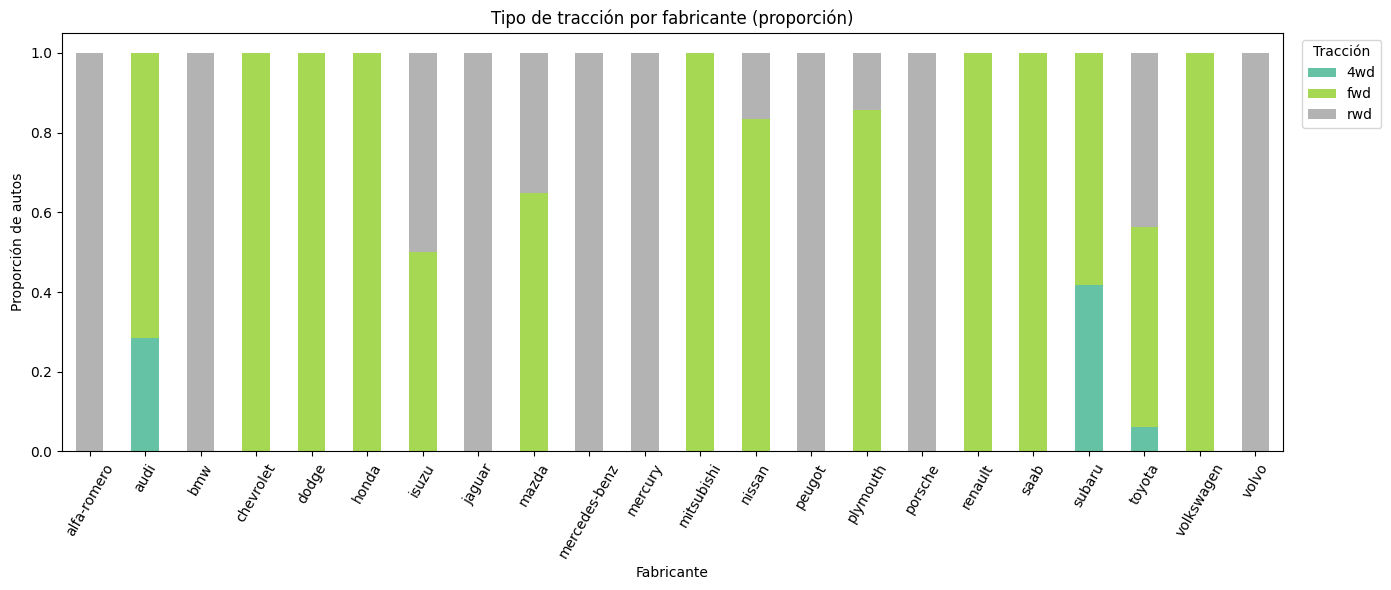

In [10]:
# Barras apiladas normalizadas: proporción de cada tipo de tracción por fabricante
traccion = pd.crosstab(cars_df['make'], cars_df['drive_wheels'], normalize='index')
traccion.plot(kind='bar', stacked=True, figsize=(14, 6), colormap='Set2')
plt.title('Tipo de tracción por fabricante (proporción)')
plt.xlabel('Fabricante')
plt.ylabel('Proporción de autos')
plt.legend(title='Tracción', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

Conclusión 3a: Tracción por fabricante

Al revisar la gráfica, hay una diferencia bastante clara entre las marcas. Por ejemplo, BMW, Mercedes-Benz, Jaguar, Porsche, Volvo, Alfa Romeo y Peugeot tienen solamente autos con tracción trasera en estos datos. En cambio, marcas como Honda, Chevrolet, Dodge, Mitsubishi, Volkswagen, Renault y Saab aparecen únicamente con tracción delantera.

También hay marcas como Mazda, Nissan, Plymouth e Isuzu que utilizan ambos tipos de tracción, dependiendo del modelo, y Toyota, que es la única que combina los tres tipos. La tracción en las cuatro ruedas es mucho menos común y solo aparece en Subaru, Audi y Toyota.

Esto tiene sentido porque la tracción trasera normalmente se encuentra en autos deportivos o de mayor precio, mientras que la delantera suele ser más económica de fabricar.

El tipo de tracción puede tener cierta relación con el precio de los autos, algo que sería interesante revisar más adelante en el análisis.

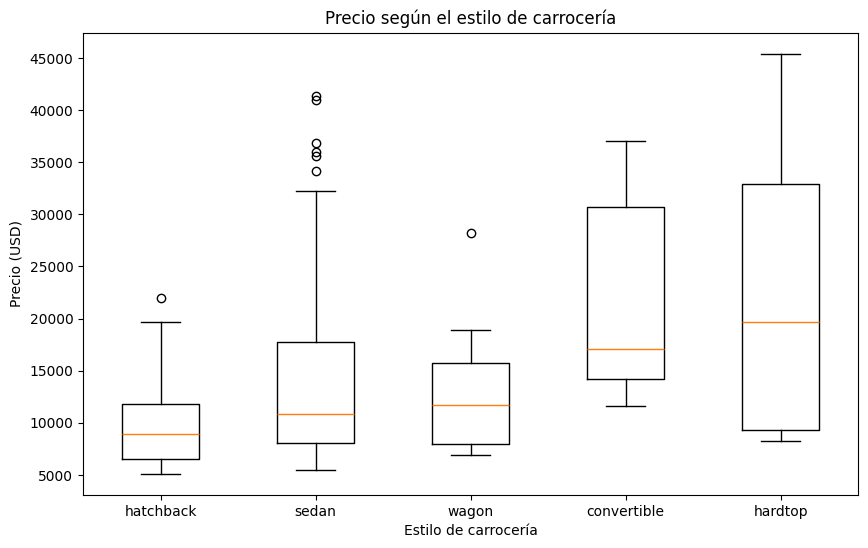

In [11]:
# Diagrama de cajas: precio según el estilo de carrocería
orden = cars_df.groupby('body_style')['price'].median().sort_values().index
plt.figure(figsize=(10, 6))
plt.boxplot([cars_df.loc[cars_df['body_style'] == b, 'price'] for b in orden], tick_labels=orden)
plt.title('Precio según el estilo de carrocería')
plt.xlabel('Estilo de carrocería')
plt.ylabel('Precio (USD)')
plt.show()

Conclusión 3b: Precio según el estilo de carrocería

La gráfica muestra que existe una relación entre el tipo de carrocería y el precio de los autos. Los hatchback son los más económicos, con una mediana cercana a los 9,000 dólares, seguidos por los sedán, con aproximadamente 11,000 dólares, y los wagon, con 11,700. Por otro lado, los convertibles y hardtop presentan los precios más altos, con medianas de alrededor de 17,000 y 19,700 dólares.

También se puede observar que los precios de los convertibles y hardtop varían bastante, ya que existen modelos económicos y otros mucho más caros. Esto se refleja en el tamaño de las cajas de la gráfica. En cambio, los hatchback tienen precios más bajos y se concentran en un rango más pequeño.

En el caso de los sedán, aparecen algunos valores atípicos por encima de los 34,000 dólares, posiblemente relacionados con modelos de lujo de marcas como Mercedes-Benz, BMW o Jaguar.

En general, los resultados muestran que el estilo de carrocería tiene relación con el precio, aunque no es el único factor. La marca y las características de cada vehículo también pueden influir de manera importante.

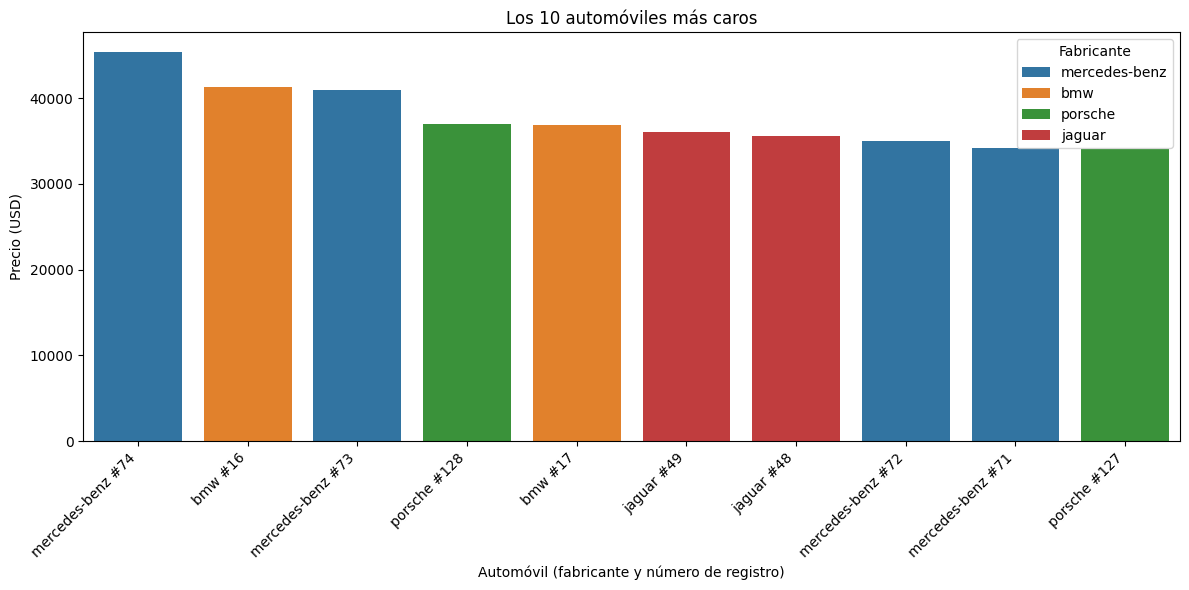

In [12]:
# Barras: los 10 autos más caros, de mayor a menor, con color por fabricante
top10 = cars_df.nlargest(10, 'price').reset_index()
top10['auto'] = top10['make'] + ' #' + top10['index'].astype(str)
plt.figure(figsize=(12, 6))
sns.barplot(data=top10, x='auto', y='price', hue='make', dodge=False)
plt.title('Los 10 automóviles más caros')
plt.xlabel('Automóvil (fabricante y número de registro)')
plt.ylabel('Precio (USD)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Fabricante')
plt.tight_layout()
plt.show()

Conclusión 3c: Los 10 autos más caros

La gráfica muestra que los diez autos más caros pertenecen solamente a cuatro marcas: Mercedes-Benz, BMW, Jaguar y Porsche. Mercedes-Benz tiene la mayor presencia, con cuatro autos, incluyendo el más caro de todo el conjunto, con un precio de 45,400 dólares. Le siguen BMW, con dos autos que superan los 36,000 dólares, Jaguar, con dos alrededor de los 36,000, y Porsche, con dos de 34,028 y 37,028 dólares.

Un dato interesante es que todos estos vehículos cuestan más de 34,000 dólares, mientras que la mitad de los autos del conjunto tiene un precio inferior a 10,295 dólares. Esta diferencia ayuda a explicar por qué el histograma de precios tiene una cola larga hacia la derecha y por qué aparecen valores atípicos en el diagrama de cajas.

En general, los resultados muestran que la marca tiene una relación importante con el precio de los autos. Además, estas cuatro marcas coinciden con las que utilizan únicamente tracción trasera en la gráfica 3a, lo que también podría indicar una relación entre el tipo de tracción y el precio.

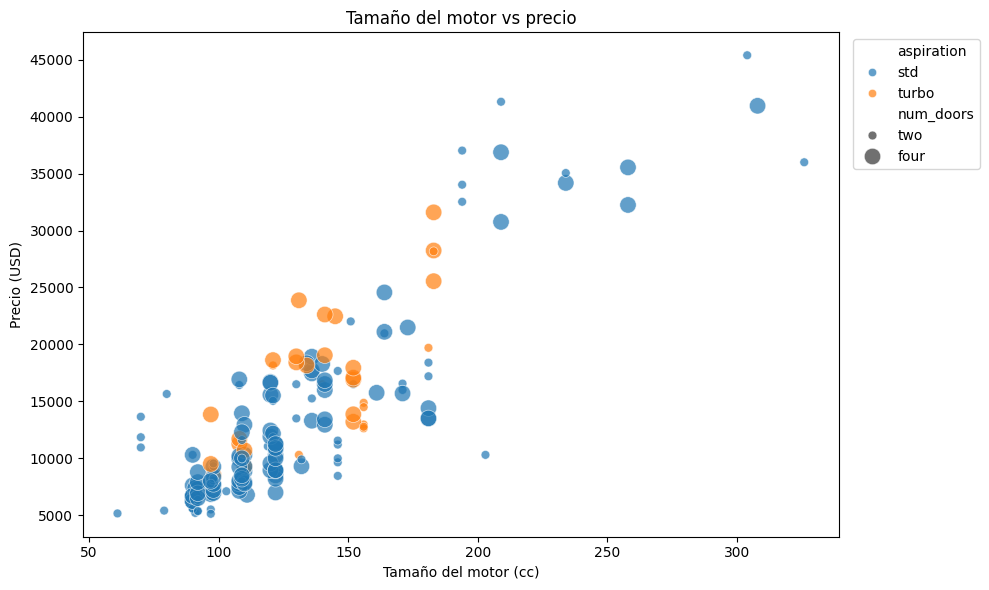

In [13]:
# Dispersión: tamaño del motor vs precio, color = aspiración, tamaño = número de puertas
plt.figure(figsize=(10, 6))
sns.scatterplot(data=cars_df, x='engine_size', y='price',
                hue='aspiration', size='num_doors', sizes={'two': 40, 'four': 140},
                alpha=0.7)
plt.title('Tamaño del motor vs precio')
plt.xlabel('Tamaño del motor (cc)')
plt.ylabel('Precio (USD)')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

Conclusión 3d: Tamaño del motor vs precio

La gráfica muestra que existe una relación bastante clara entre el tamaño del motor y el precio de los autos. En general, mientras más grande es el motor, mayor es el precio. La mayoría de los vehículos tienen motores de entre 90 y 130 cc, con precios que van de 5,000 a 15,000 dólares. En cambio, casi todos los autos con motores de más de 190 cc superan los 30,000 dólares y algunos llegan hasta los 45,400.

También se observa que los autos turbo, representados en color naranja, tienen motores de tamaño mediano, entre 95 y 185 cc, y generalmente son más caros que otros vehículos con motores similares. Varios tienen precios entre 18,000 y 28,000 dólares. Sin embargo, los autos más caros del conjunto no son turbo, sino vehículos de lujo con motores grandes de aspiración normal.

En cuanto al número de puertas, no se observa una diferencia tan clara. Los autos de dos y cuatro puertas aparecen distribuidos en casi todos los rangos de precio, por lo que esta característica no parece tener una relación tan importante con el costo.

En general, el tamaño del motor es la variable que muestra una relación más clara con el precio en esta gráfica, mientras que el número de puertas parece tener menor importancia.

4. Genera un mapa de calor de la matriz de correlación entre las variables numéricas del conjunto de datos, mostrando los valores de correlación en cada celda.
* ¿Cuáles son las tres variables más correlacionadas con el precio?

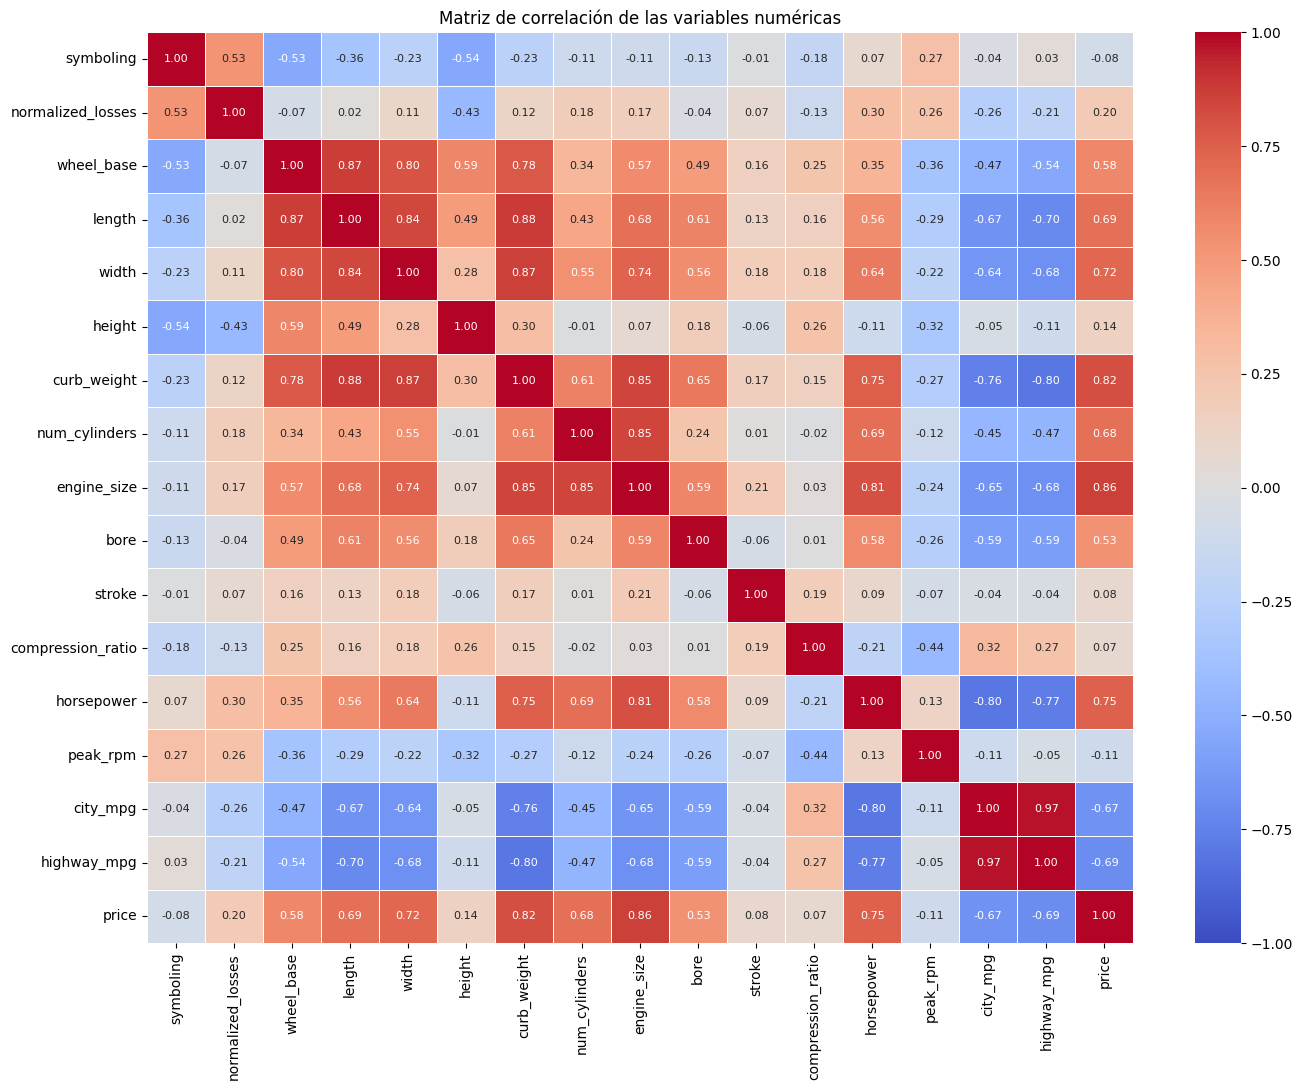

engine_size    0.860343
curb_weight    0.819817
horsepower     0.749844
Name: price, dtype: float64

In [14]:
# Mapa de calor de la matriz de correlación, con el valor en cada celda
corr = num_df.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={'size': 8})
plt.title('Matriz de correlación de las variables numéricas')
plt.tight_layout()
plt.show()

# Las tres variables más correlacionadas con el precio
corr['price'].drop('price').sort_values(ascending=False).head(3)

Respuesta 4

Las tres variables que tienen mayor correlación con el precio son el tamaño del motor (0.86), el peso del auto sin carga (0.82) y la potencia (0.75). En los tres casos, la relación es positiva, lo que significa que los autos con motores más grandes, mayor peso y más potencia suelen tener precios más altos. Esto tiene sentido, ya que normalmente estas características se encuentran en vehículos de mayor categoría. Además, coincide con lo observado en la gráfica 3d, donde el precio aumenta conforme crece el tamaño del motor.

En el mapa de correlación también se puede ver que varias variables están relacionadas entre sí. Por ejemplo, el rendimiento en carretera (highway_mpg) tiene una correlación negativa de -0.80 con el peso, lo que indica que los autos más pesados generalmente consumen más combustible. También se observa que el largo, el ancho, el peso y el tamaño del motor tienen relaciones fuertes entre ellos.

Esto significa que algunas variables contienen información muy parecida sobre las características del vehículo. Por esta razón, aplicar PCA puede ser útil, ya que permite reducir la cantidad de variables y resumir la información en menos componentes que no están correlacionados entre sí.

Por otro lado, variables como stroke (0.08), compression_ratio (0.07) y symboling (-0.08) presentan correlaciones muy bajas con el precio, por lo que no muestran una relación lineal importante.

En general, los resultados indican que el tamaño del motor, el peso y la potencia son las características numéricas más relacionadas con el precio de los autos.

En el análisis de correlación se observa que existen muchos pares de variables altamente correlacionadas, lo que puede afectar el desempeño de los modelos de regresión. PCA resulta útil no solo para reducir la dimensionalidad, sino también porque los componentes principales son ortogonales entre sí, es decir, tienen correlación cero, evitando problemas de multicolinealidad. Esto lo podrás comprobrar más adelante.

# Ingeniería de características

5. Realiza las siguientes operaciones de ingeniería de características en las variables numéricas:
* Considera `price` como la variable objetivo y guárdala en `y`. Separa los predictores numéricos en `X`. Con base en estos datos, ¿cuántos componentes principales se generarán al aplicar PCA?
* Aplica `SimpleImputer` sobre `X` para tratar los valores faltantes, justificando la estrategia de imputación seleccionada.
* Realiza el escalamiento del conjunto `X` ya imputado, para que todas las variables contribuyan equitativamente y ninguna domine el análisis por tener una escala mayor.

PCA está diseñado principalmente para variables numéricas y funciona encontrando combinaciones lineales de las variables originales que capturan la mayor varianza en los datos. Normalmente se recomienda eliminar las variables categóricas antes de aplicar PCA y luego concatenarlas nuevamente con los resultados de PCA si se desea.

In [15]:
# y = variable objetivo (precio); X = predictores numéricos
y = cars_df['price']
X = num_df.drop(columns='price')
print('Predictores numéricos en X:', X.shape[1])
print('Componentes principales que generará PCA:', X.shape[1])

# Imputar faltantes con la mediana
imputer = SimpleImputer(strategy='median')
X_imputado = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)
print('Faltantes después de imputar:', X_imputado.isna().sum().sum())

# Escalar para que todas las variables pesen igual
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_imputado)
print('Media después de escalar:', X_escalado.mean().round(2), '| Desviación estándar:', X_escalado.std().round(2))

Predictores numéricos en X: 16
Componentes principales que generará PCA: 16
Faltantes después de imputar: 0
Media después de escalar: 0.0 | Desviación estándar: 1.0


Respuesta 5

Para comenzar, se separó el precio como variable objetivo (y) y se utilizaron las otras 16 variables numéricas como datos de entrada (X). Al aplicar PCA se pueden obtener hasta 16 componentes principales, aunque más adelante se analizará cuántos son realmente necesarios para representar la mayor parte de la información.

Para completar los datos faltantes, se utilizó SimpleImputer con la mediana. Se eligió este método porque algunas variables presentan valores extremos. Por ejemplo, horsepower llega hasta 288, mientras que la mayoría de los autos tiene una potencia cercana a 95. Algo parecido ocurre con normalized_losses, donde algunos valores son mucho más altos que el resto. En estos casos, la mediana es una mejor opción porque no se ve tan afectada por los valores extremos como el promedio.

Además, la cantidad de datos faltantes es relativamente baja, con un máximo del 20% en normalized_losses y menos del 2% en las demás columnas. Esto permite completar los valores sin alterar demasiado la distribución original, aunque siempre puede existir algún efecto. Después de aplicar el método, ya no quedaron valores faltantes.

Finalmente, se utilizó StandardScaler para poner todas las variables en una misma escala, con promedio 0 y desviación estándar 1. Este paso es importante porque los datos tienen unidades y rangos muy diferentes. Por ejemplo, el peso promedio de los autos está alrededor de 2,555 libras, mientras que bore y stroke tienen valores cercanos a 3.

Sin esta estandarización, PCA daría mayor importancia a las variables con números más grandes, aunque no necesariamente sean las que aportan más información. De esta manera, todas las variables pueden participar en el análisis bajo una escala comparable.

6. Aplica `PCA` a los datos escalados para proyectarlos en el nuevo espacio de vectores.
* Asigna nombres descriptivos a los componentes principales en el dataframe resultante, utilizando la convención PC1, PC2, PC3, y así sucesivamente.
* Genera un mapa de calor con la matriz de correlaciones de los componentes principales para verificar que sean independientes entre sí.

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,1.370499,-1.130802,-1.013703,0.502983,0.657052,0.174955,-0.008520,0.118635,-0.111688
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,0.400032,0.293338,0.168137,0.039239,-0.022832,-0.078891,-0.391786,0.009265,0.053641
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,0.870186,0.015429,-0.447054,-0.055376,-0.416053,-0.049431,0.079357,-0.198402,0.046303


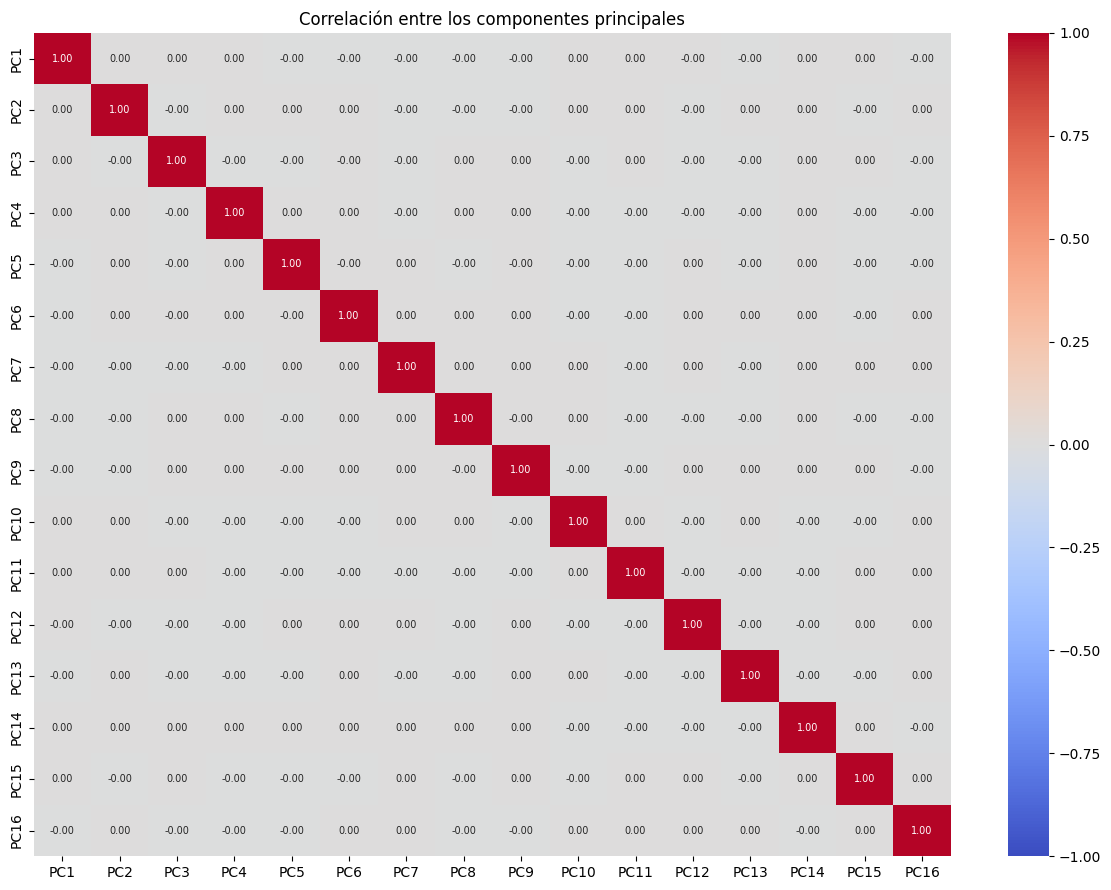

In [16]:
# Aplicar PCA a los datos escalados y nombrar los componentes PC1, PC2, ...
pca = PCA()
X_pca = pca.fit_transform(X_escalado)
nombres_pc = [f'PC{i+1}' for i in range(X_pca.shape[1])]
pca_df = pd.DataFrame(X_pca, columns=nombres_pc)
display(pca_df.head())

# Mapa de calor de las correlaciones entre componentes
plt.figure(figsize=(12, 9))
sns.heatmap(pca_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            annot_kws={'size': 7})
plt.title('Correlación entre los componentes principales')
plt.tight_layout()
plt.show()

Respuesta 6

Se aplicó PCA a los datos después de completar los valores faltantes y estandarizar las variables. Como resultado, se obtuvo una nueva tabla con los mismos 205 autos, pero ahora con 16 componentes principales, identificados como PC1 hasta PC16, en lugar de las 16 variables originales.

Cada componente combina información de las variables iniciales. Por ejemplo, el primer auto tiene un valor de -0.92 en PC1 y -2.40 en PC2. También se observa que los dos primeros registros tienen exactamente los mismos valores en todos los componentes. Esto se debe a que son dos Alfa Romeo con las mismas características técnicas y únicamente cambia su precio, que no se incluyó en el PCA.

Al revisar el mapa de calor, se puede ver que los componentes no están correlacionados entre sí. La diagonal tiene un valor de 1.00 porque cada componente se compara consigo mismo, mientras que las demás celdas muestran valores de 0.00.

Esto es diferente a lo observado en la matriz de correlación original, donde variables como el largo, el ancho, el peso y el tamaño del motor estaban muy relacionadas.

En general, PCA permite reorganizar la información en componentes que no están correlacionados entre sí, evitando la multicolinealidad entre ellos. Esto puede ser útil más adelante para crear modelos utilizando menos variables, siempre que se conserven los componentes que explican la mayor parte de la variación de los datos.

7. Obtén el porcentaje de varianza explicada por cada componente.
* Grafica la curva de varianza acumulada para determinar el número mínimo de componentes principales que explican más del 90% de la varianza total.

,varianza_%,acumulada_%
PC1,44.55,44.55
PC2,17.93,62.48
PC3,8.58,71.05
PC4,6.44,77.49
PC5,5.74,83.23
PC6,4.78,88.01
PC7,3.25,91.26
PC8,2.73,93.98
PC9,1.94,95.92
PC10,1.55,97.48


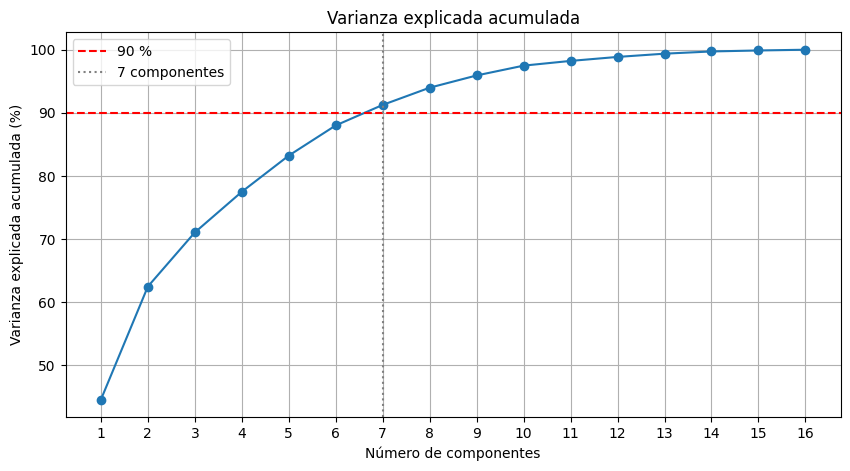

Mínimo de componentes para explicar más del 90 %: 7


In [17]:
# Porcentaje de varianza explicada por componente y acumulada
varianza = pd.DataFrame({
    'varianza_%': (pca.explained_variance_ratio_ * 100).round(2),
    'acumulada_%': (pca.explained_variance_ratio_.cumsum() * 100).round(2)
}, index=nombres_pc)
display(varianza)

# Curva de varianza acumulada con la línea del 90 %
acumulada = pca.explained_variance_ratio_.cumsum()
n_90 = int(np.argmax(acumulada > 0.90)) + 1
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(acumulada) + 1), acumulada * 100, marker='o')
plt.axhline(90, color='red', linestyle='--', label='90 %')
plt.axvline(n_90, color='gray', linestyle=':', label=f'{n_90} componentes')
plt.xticks(range(1, len(acumulada) + 1))
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada (%)')
plt.title('Varianza explicada acumulada')
plt.legend()
plt.grid(True)
plt.show()
print('Mínimo de componentes para explicar más del 90 %:', n_90)

Respuesta 7

El primer componente principal (PC1) explica el 44.55% de la variación de los datos, es decir, casi la mitad de toda la información. El segundo componente (PC2) aporta otro 17.93%, por lo que entre los dos explican el 62.48%. A partir del tercer componente, la aportación va disminuyendo. PC3 explica el 8.58%, PC4 el 6.44% y PC5 el 5.74%. Del componente 11 en adelante, cada uno aporta menos del 1%.

En la gráfica de varianza acumulada se observa que la curva sube rápidamente al principio y después comienza a estabilizarse. Esto significa que la mayor parte de la variación de los datos se encuentra en los primeros componentes y que los últimos aportan cada vez menos.

Con seis componentes se logra explicar el 88.01% de la varianza, lo que todavía está por debajo del 90%. Al incluir el séptimo componente, el porcentaje aumenta al 91.26%.

Por lo tanto, se necesitan como mínimo 7 componentes para superar el 90% de la varianza explicada. Esto permite reducir las 16 variables numéricas originales a solo 7 componentes, conservando el 91.26% de la variación de los datos y dejando sin explicar únicamente el 8.74%.

En general, esta reducción permite trabajar con menos variables, sin perder gran parte de la información original y evitando la correlación entre los componentes.

8. Imprime la información de los componentes seleccionados (cargas o pesos de las variables originales) para interpretar qué variables contribuyen más a cada componente principal.
* Dibuja un diagrama de barras que muestre qué variables originales aportan más al primer componente principal (PC1), para visualizar su influencia relativa.

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
symboling,-0.10,-0.40,0.27,-0.07,-0.37,0.17,0.13
normalized_losses,0.02,-0.33,0.31,-0.34,-0.38,-0.49,-0.32
wheel_base,0.30,0.26,-0.03,-0.23,-0.00,-0.18,-0.11
length,0.34,0.14,-0.04,-0.19,-0.07,-0.08,-0.01
width,0.33,0.06,0.11,-0.10,-0.02,-0.11,0.14
height,0.11,0.42,-0.28,-0.19,-0.02,-0.21,-0.00
curb_weight,0.36,0.02,0.08,-0.03,-0.04,-0.01,0.06
num_cylinders,0.25,-0.11,0.18,0.55,0.24,-0.35,-0.07
engine_size,0.33,-0.08,0.20,0.30,0.11,0.02,-0.07
bore,0.26,0.00,-0.14,0.04,-0.37,0.51,0.13


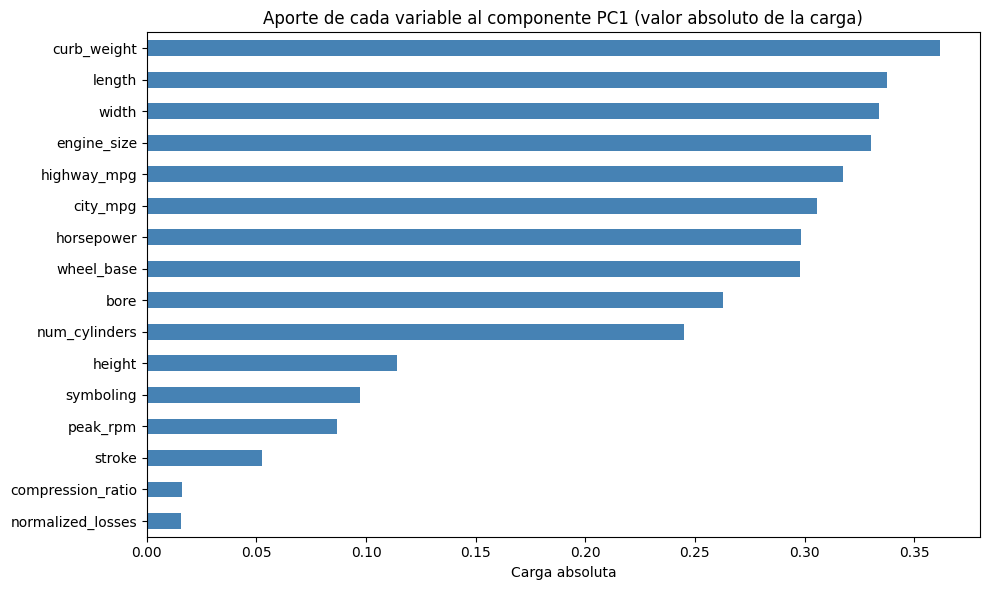

In [18]:
# Cargas de las variables originales en los 7 componentes elegidos
cargas = pd.DataFrame(pca.components_[:n_90].T, index=X.columns, columns=nombres_pc[:n_90])
display(cargas.round(2))

# Variables que más aportan a PC1 (valor absoluto)
aporte_pc1 = cargas['PC1'].abs().sort_values()
plt.figure(figsize=(10, 6))
aporte_pc1.plot(kind='barh', color='steelblue')
plt.title('Aporte de cada variable al componente PC1 (valor absoluto de la carga)')
plt.xlabel('Carga absoluta')
plt.tight_layout()
plt.show()

Respuesta 8

La tabla de cargas permite identificar qué tanto aporta cada variable original a los 7 componentes principales seleccionados. Mientras más alejado de cero esté el valor, ya sea positivo o negativo, mayor es la importancia de esa variable dentro del componente.

En el primer componente (PC1), que explica el 44.55% de la variación, las variables con mayor peso son el peso del auto sin carga (0.36), el largo (0.34), el ancho (0.33) y el tamaño del motor (0.33). También tienen una participación importante la potencia, la distancia entre ejes y el rendimiento de combustible en ciudad y carretera, con valores cercanos a 0.30.

En el caso del consumo de combustible, la relación es negativa, ya que los autos más grandes y pesados generalmente recorren menos millas por galón. Por esta razón, PC1 se puede interpretar como un componente relacionado con el tamaño y la potencia del vehículo, que permite diferenciar los autos pequeños y ligeros de los más grandes y potentes. En cambio, variables como compression_ratio y normalized_losses tienen una participación muy baja, cercana a 0.02.

Los demás componentes representan otras características. En PC2 destacan la altura (0.42), el nivel de riesgo del seguro o symboling (-0.40) y la relación de compresión (0.36), por lo que parece estar más relacionado con el tipo de vehículo. En PC3 sobresalen stroke (0.51) y compression_ratio (0.49), ambas relacionadas con las características del motor. Por su parte, en PC4 la variable más importante es el número de cilindros (0.55), frente a stroke (-0.43). En PC5 sobresale stroke (0.57) frente a normalized_losses (-0.38), symboling (-0.37) y bore (-0.37); en PC6 destacan bore (0.51) y normalized_losses (-0.49), y en PC7 la relación de compresión (0.61) y peak_rpm (0.60).

En general, los resultados coinciden con el análisis de correlación anterior, ya que las variables relacionadas con el tamaño, el peso y la potencia quedaron agrupadas principalmente en PC1.

Esto también permite considerar que PC1 podría ser uno de los componentes más útiles para explicar el precio de los autos en la Actividad 8, aunque será necesario comprobarlo con el análisis correspondiente.

9. Codifica las variables categóricas mediante *One-Hot Encoding* y utiliza el parámetro `drop='first'` para evitar problemas de multicolinealidad entre las variables dummy generadas.

In [19]:
# Codificar las variables categóricas con One-Hot Encoding (drop='first')
encoder = OneHotEncoder(drop='first', sparse_output=False)
cat_codificadas = encoder.fit_transform(cat_df)
cat_cod_df = pd.DataFrame(cat_codificadas, columns=encoder.get_feature_names_out(cat_df.columns))
print('Variables categóricas originales:', cat_df.shape[1])
print('Columnas después de codificar:', cat_cod_df.shape[1])
display(cat_cod_df.head())

Variables categóricas originales: 9
Columnas después de codificar: 44


,make_audi,make_bmw,make_chevrolet,make_dodge,make_honda,make_isuzu,make_jaguar,make_mazda,make_mercedes-benz,make_mercury,...,engine_type_ohcf,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


Respuesta 9

Para trabajar con las 9 variables categóricas, como la marca, el combustible, la aspiración, el número de puertas, la carrocería, la tracción, la ubicación del motor, el tipo de motor y el sistema de combustible, se utilizó One-Hot Encoding. Este método permite convertir las categorías en valores numéricos para que puedan utilizarse en los modelos. Cada categoría se representa con una columna que tiene un valor de 1 cuando el auto pertenece a ella y 0 cuando no.

También se utilizó drop='first' para eliminar la primera categoría de cada variable y evitar información repetida. Esto no significa que se pierda esa categoría, ya que se puede identificar cuando todas las demás columnas de la misma variable tienen valor 0.

Por ejemplo, en la variable marca, Alfa Romeo quedó como categoría de referencia. Por eso, los tres primeros registros tienen 0 en todas las columnas correspondientes a las marcas, mientras que los registros 3 y 4 tienen un valor de 1 en make_audi. Este procedimiento también ayuda a evitar problemas de multicolinealidad al utilizar modelos de regresión.

Como resultado, las 9 variables categóricas se transformaron en 44 columnas numéricas. La marca fue la variable que generó más columnas, debido a que existen 22 fabricantes diferentes en el conjunto de datos.

En general, esta transformación permite utilizar la información categórica en los modelos sin perder la posibilidad de distinguir las características de cada vehículo.

10. Conjunta, en un dataframe, las valores proyectados en los componentes seleccionados (mínimo), las transformaciones obtenidas de las variables categóricas y la variable de salida.
* Almacena el dataframe resultante en archivo.

In [20]:
# Conjunto final: 7 componentes elegidos + variables codificadas + precio
final_df = pd.concat([pca_df[nombres_pc[:n_90]],
                      cat_cod_df,
                      y.reset_index(drop=True)], axis=1)
print('Dimensiones del conjunto final:', final_df.shape)
print('Faltantes en el conjunto final:', final_df.isna().sum().sum())
display(final_df.head())

# Guardar en archivo
final_df.to_csv('automobile_pca_final.csv', index=False)
print('Archivo guardado: automobile_pca_final.csv')

Dimensiones del conjunto final: (205, 52)
Faltantes en el conjunto final: 0


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,make_audi,make_bmw,make_chevrolet,...,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi,price
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13495
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13950
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,17450


Archivo guardado: automobile_pca_final.csv


Respuesta 10

Para preparar el conjunto de datos final, se combinaron tres partes: los 7 componentes principales (PC1 a PC7), que conservan el 91.26% de la variación de las 16 variables numéricas originales; las 44 columnas obtenidas al codificar las variables categóricas; y el precio, que será la variable que se busca predecir.

Como resultado, se obtuvo una tabla con 205 autos y 52 columnas en total (7 + 44 + 1), sin valores faltantes.

En comparación con el conjunto original de 26 columnas, los datos ahora están mejor preparados para crear un modelo de regresión. Todas las variables son numéricas, no hay datos faltantes y las variables originales se redujeron a componentes principales que no están correlacionados entre sí. Además, las variables categóricas se transformaron en columnas numéricas, evitando información redundante dentro de cada categoría.

Finalmente, el conjunto de datos se guardó en el archivo automobile_pca_final.csv, que puede servir como base para el modelo de regresión lineal de la Actividad 8.

En general, este proceso permitió organizar y transformar los datos para facilitar el análisis y la construcción del modelo.

---

**Declaración de uso de IA**


En esta actividad se utilizó Claude (Anthropic, modelo Claude Opus 5.5) como apoyo para guiar paso a paso la estructura del código en Python, revisar que cada pregunta de la rúbrica quedara respondida y mejorar la redacción de las conclusiones. Los resultados, gráficas y números fueron generados y verificados por el equipo al ejecutar la libreta, y las interpretaciones se revisaron para que reflejaran lo observado en los datos.

Referencia: Anthropic. (2026). Claude (versión Opus 5.5) [Modelo de lenguaje grande]. https://claude.ai
